# 02 · HSV baseline detector

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/barak2rozenfeld/led-vision-lab/blob/master/notebooks/02_hsv_baseline.ipynb)

The simplest method in LED Vision Lab: no training, only image statistics. It answers *"is a compact region
much brighter than its surroundings, and does it glow?"*

1. Resize to 128 × 128 and convert to HSV.
2. Estimate the background brightness with a large median blur of the V channel.
3. **Score** = brightness above background + a bonus for saturated colour.
4. Keep pixels with a high score, clean the mask, and find connected blobs.
5. For each blob: 95th-percentile score + **halo**: how much light spills into a ring around it
   (lit LEDs glow; shiny pads and grey lenses do not).
6. ON when the best blob's score passes a threshold; confidence grows with the distance from it.

The thresholds are calibrated on the **train** split only. All reported numbers come from the **test** split.
Code: `src/led_vision/detectors/hsv.py`, calibration: `src/led_vision/training/hsv_calibration.py`.

## Setup

In [1]:
import os
import sys
from pathlib import Path

REPO_URL = "https://github.com/barak2rozenfeld/led-vision-lab.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not Path("led-vision-lab").exists():
        !git clone --depth 1 {REPO_URL}
    os.chdir("led-vision-lab")
    !pip install -q -e .
elif Path.cwd().name == "notebooks":
    os.chdir("..")  # running locally: work from the repository root

sys.path.insert(0, str(Path.cwd() / "src"))  # importable without restarting the kernel
print("Working directory:", Path.cwd())

Working directory: C:\CursorProjects\led-vision-lab


## Parameters
The dataset is generated if needed (same settings as notebook 01).

In [2]:
SCENES = 20_000   # same as configs/dataset/pcb_20k.yaml; lower it (e.g. 4_000) for a quick run
SEED = 77         # same seed as the committed reports
WORKERS = os.cpu_count() or 2
DATASET = Path("data/generated_20k" if SCENES == 20_000 else f"data/generated_{SCENES}")

RUN_CALIBRATION = False   # True re-runs the grid search (~10 min on Colab); False uses configs/detectors/hsv.yaml
CALIBRATION_IMAGES = 2_000

In [3]:
import json

if (DATASET / "metadata.csv").is_file():
    print(f"Reusing existing dataset in {DATASET}")
else:
    !{sys.executable} scripts/generate_dataset.py --config configs/dataset/pcb_20k.yaml --total {SCENES} --seed {SEED} --output {DATASET} --workers {WORKERS}

Reusing existing dataset in data\generated_20k


## Inside the detector
`HSVDetector.explain()` returns the intermediate maps for one image.

HsvConfig(work_size=128, background_kernel_frac=0.9, v_min=80, excess_min=35.0, saturation_weight=0.5, min_area_frac=0.0015, halo_weight=1.0, on_threshold=100.0, confidence_scale=18.0)


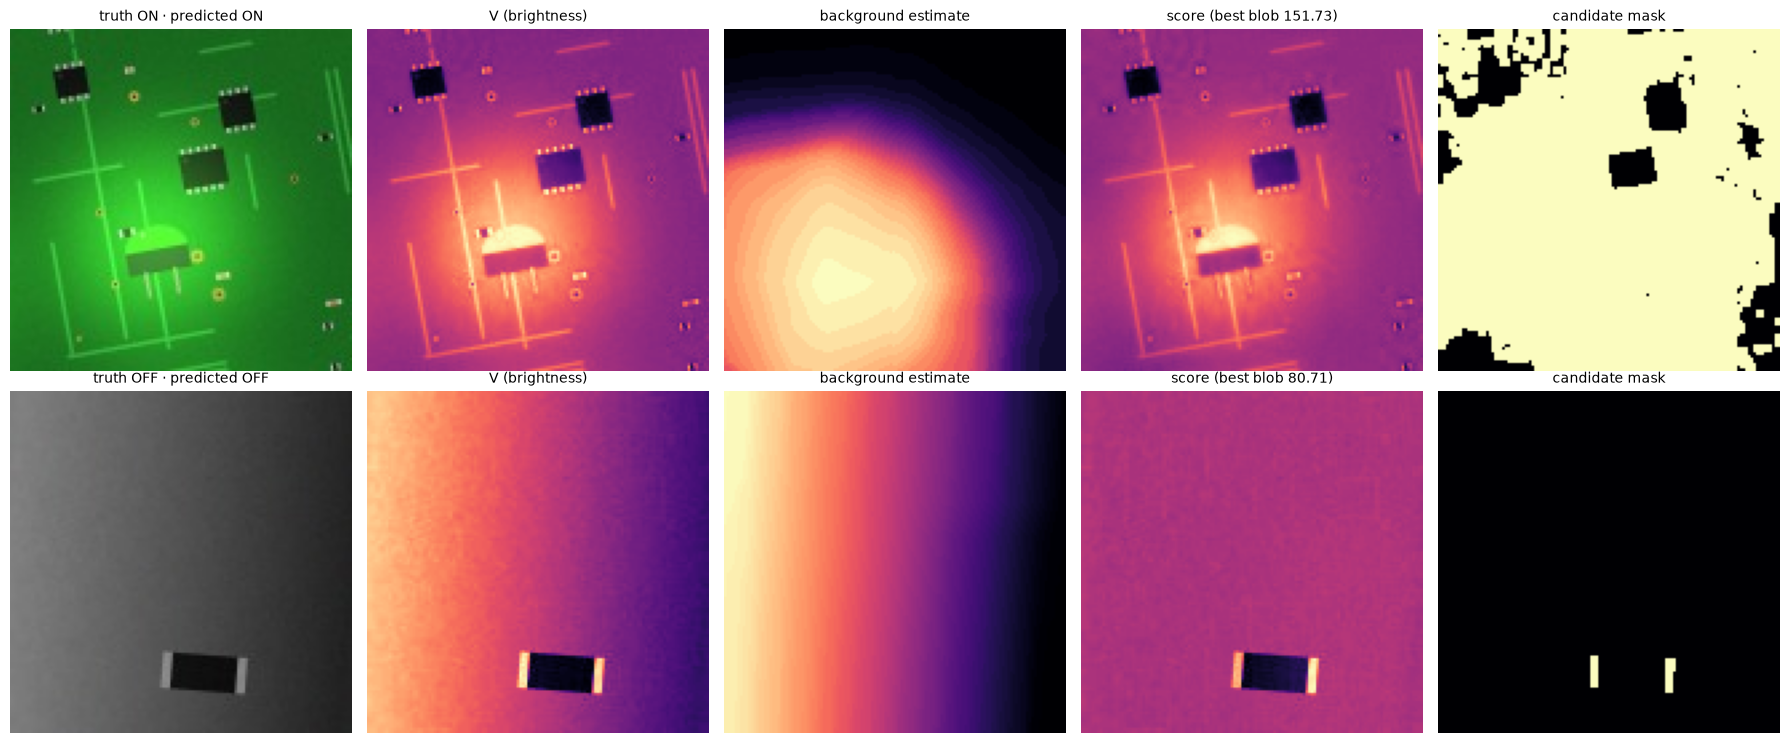

In [4]:
import csv

import cv2
import matplotlib.pyplot as plt
import numpy as np

from led_vision.detectors.hsv import HSVDetector, load_hsv_config

detector = HSVDetector(load_hsv_config(Path("configs/detectors/hsv.yaml")))
print(detector.config)

rows = [r for r in csv.DictReader((DATASET / "metadata.csv").open(encoding="utf-8"))
        if r["split"] == "test" and r["size"] == "128"]
examples = [next(r for r in rows if r["state"] == s and r["difficulty"] == "easy") for s in ("on", "off")]

fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
for row_axes, r in zip(axes, examples):
    img = cv2.imread(str(DATASET / r["filepath"]))
    maps, result = detector.explain(img), detector.detect(img)
    panels = [(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), f"truth {r['state'].upper()} · predicted {result.state}"),
              (maps["value"], "V (brightness)"), (maps["background"], "background estimate"),
              (maps["score"], f"score (best blob {result.debug['score']})"), (maps["mask"], "candidate mask")]
    for ax, (data, title) in zip(row_axes, panels):
        ax.imshow(data, cmap=None if data.ndim == 3 else "magma")
        ax.set_title(title, fontsize=10)
        ax.axis("off")
fig.tight_layout()
plt.show()

## Calibration (train split)

Using the committed configs/detectors/hsv.yaml


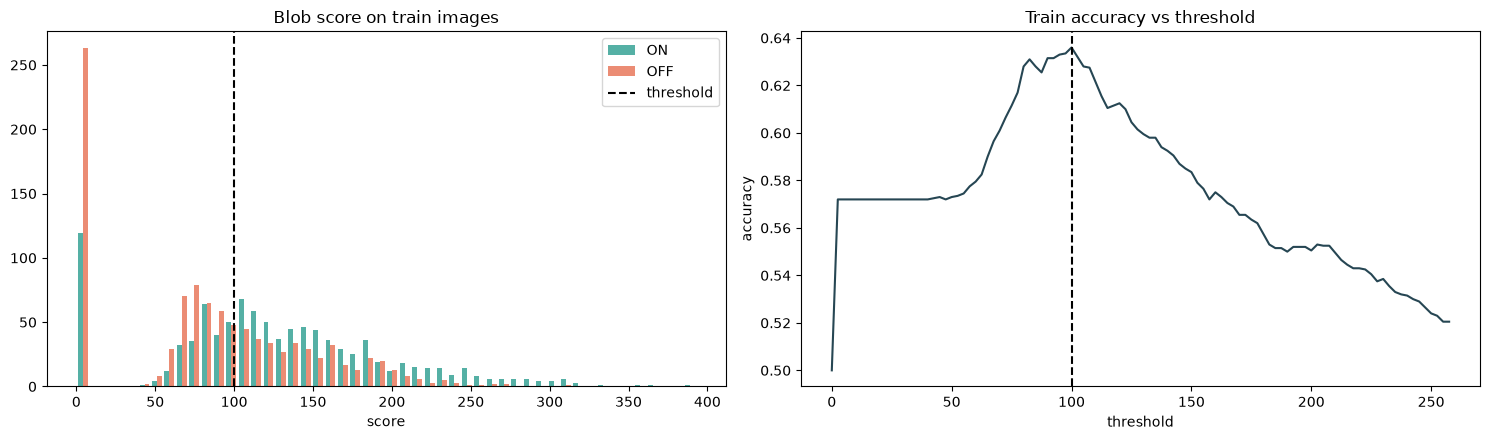

In [5]:
from dataclasses import replace

from led_vision.benchmark.runner import load_samples
from led_vision.training.hsv_calibration import calibrate_hsv

train = load_samples(DATASET, "train", 128, CALIBRATION_IMAGES, seed=0)
train_images = [(s.state == "ON", cv2.imread(str(s.path))) for s in train]

if RUN_CALIBRATION:
    result = calibrate_hsv(train_images, detector.config,
                           progress=lambda t: print(f"  {t.params} -> {t.accuracy:.4f}"))
    print("best:", result.best_params(), f"train accuracy {result.best.accuracy:.4f}")
    detector = HSVDetector(replace(detector.config, **result.best_params()))
else:
    print("Using the committed configs/detectors/hsv.yaml")

scores = np.array([detector.detect(img).debug["score"] for _, img in train_images])
truth = np.array([on for on, _ in train_images])
thresholds = np.arange(0, 260, 2.5)
accuracy = [((scores >= t) == truth).mean() for t in thresholds]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
ax1.hist([scores[truth], scores[~truth]], bins=50, label=["ON", "OFF"], color=["#2a9d8f", "#e76f51"], alpha=0.8)
ax1.axvline(detector.config.on_threshold, color="k", ls="--", label="threshold")
ax1.set_title("Blob score on train images"); ax1.set_xlabel("score"); ax1.legend()
ax2.plot(thresholds, accuracy, color="#264653")
ax2.axvline(detector.config.on_threshold, color="k", ls="--")
ax2.set_title("Train accuracy vs threshold"); ax2.set_xlabel("threshold"); ax2.set_ylabel("accuracy")
fig.tight_layout()
plt.show()

The two score distributions overlap heavily: many OFF scenes contain reflections or bright pads that
score like a lit LED, and dim or occluded ON LEDs score low. No single threshold can separate them, which is
the core limitation of a hand-written rule.

## Benchmark (test split)
The same runner produces `artifacts/benchmarks/summary.json`.

In [6]:
from led_vision.benchmark.runner import run_benchmark
from led_vision.detectors.service import DetectionService

test = load_samples(DATASET, "test", 128, None, seed=0)
report = run_benchmark(DetectionService({"hsv": detector}), test)
hsv = report["methods"]["hsv"]
o, lat = hsv["overall"], hsv["latency"]
print(f"{report['evaluated_images']:,} test images")
print(f"accuracy {o['accuracy']:.3f}  F1 {o['f1']:.3f}  precision {o['precision']:.3f}  recall {o['recall']:.3f}")
print(f"false ON {o['false_on']}  false OFF {o['false_off']}  latency p50 {lat['p50_ms']:.2f} ms, p95 {lat['p95_ms']:.2f} ms")
print(f"distractor scenes predicted ON: {hsv['distractor_scenes']['predicted_on']}/{hsv['distractor_scenes']['count']}")

3,000 test images
accuracy 0.641  F1 0.658  precision 0.623  recall 0.698
false ON 628  false OFF 448  latency p50 2.86 ms, p95 8.87 ms
distractor scenes predicted ON: 44/78


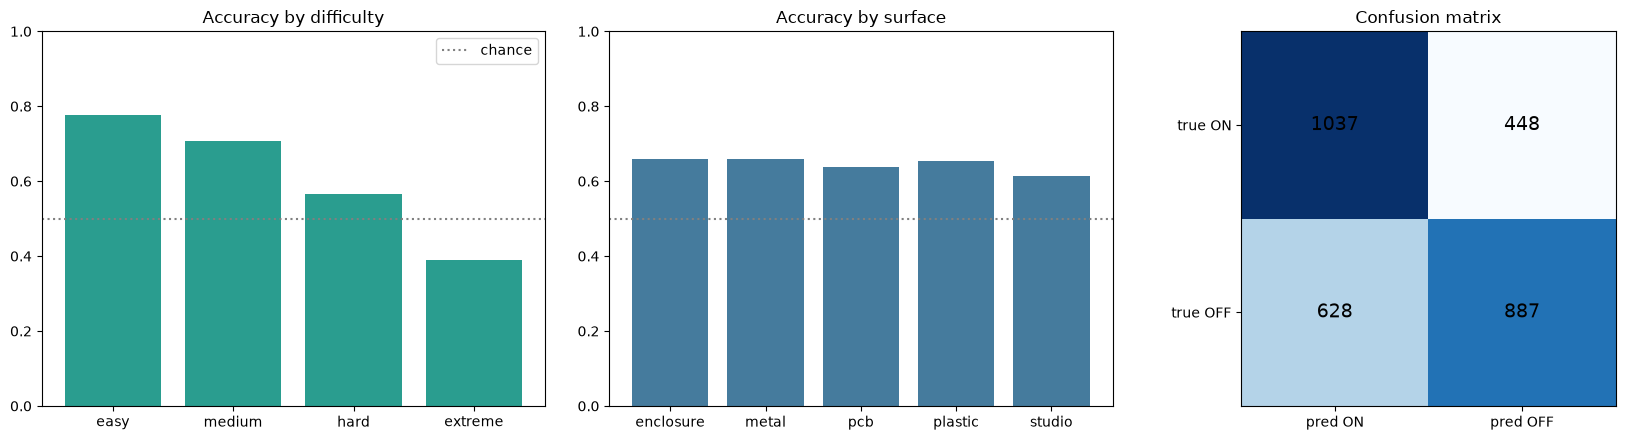

In [7]:
order = ["easy", "medium", "hard", "extreme"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

d = hsv["by_difficulty"]
axes[0].bar(order, [d[k]["accuracy"] for k in order], color="#2a9d8f")
axes[0].axhline(0.5, color="grey", ls=":", label="chance")
axes[0].set_ylim(0, 1); axes[0].set_title("Accuracy by difficulty"); axes[0].legend()

b = hsv["by_background_family"]
axes[1].bar(list(b), [v["accuracy"] for v in b.values()], color="#457b9d")
axes[1].axhline(0.5, color="grey", ls=":")
axes[1].set_ylim(0, 1); axes[1].set_title("Accuracy by surface")

c = o["confusion"]
matrix = np.array([[c["tp"], c["fn"]], [c["fp"], c["tn"]]])
axes[2].imshow(matrix, cmap="Blues")
for (i, j), v in np.ndenumerate(matrix):
    axes[2].text(j, i, str(v), ha="center", va="center", fontsize=14)
axes[2].set_xticks([0, 1], ["pred ON", "pred OFF"]); axes[2].set_yticks([0, 1], ["true ON", "true OFF"])
axes[2].set_title("Confusion matrix")
fig.tight_layout()
plt.show()

In [8]:
committed = json.loads(Path("artifacts/benchmarks/summary.json").read_text(encoding="utf-8"))
ref = committed["methods"]["hsv"]["overall"]
print(f"this run accuracy {o['accuracy']:.4f} | committed {ref['accuracy']:.4f} "
      f"(commit {committed['provenance']['git_commit']}, {committed['evaluated_images']:,} images)")

this run accuracy 0.6413 | committed 0.6413 (commit 2b749a56d, 3,000 images)


## Where it fails
The first misclassified test images of each kind; the yellow box is the blob the detector picked.

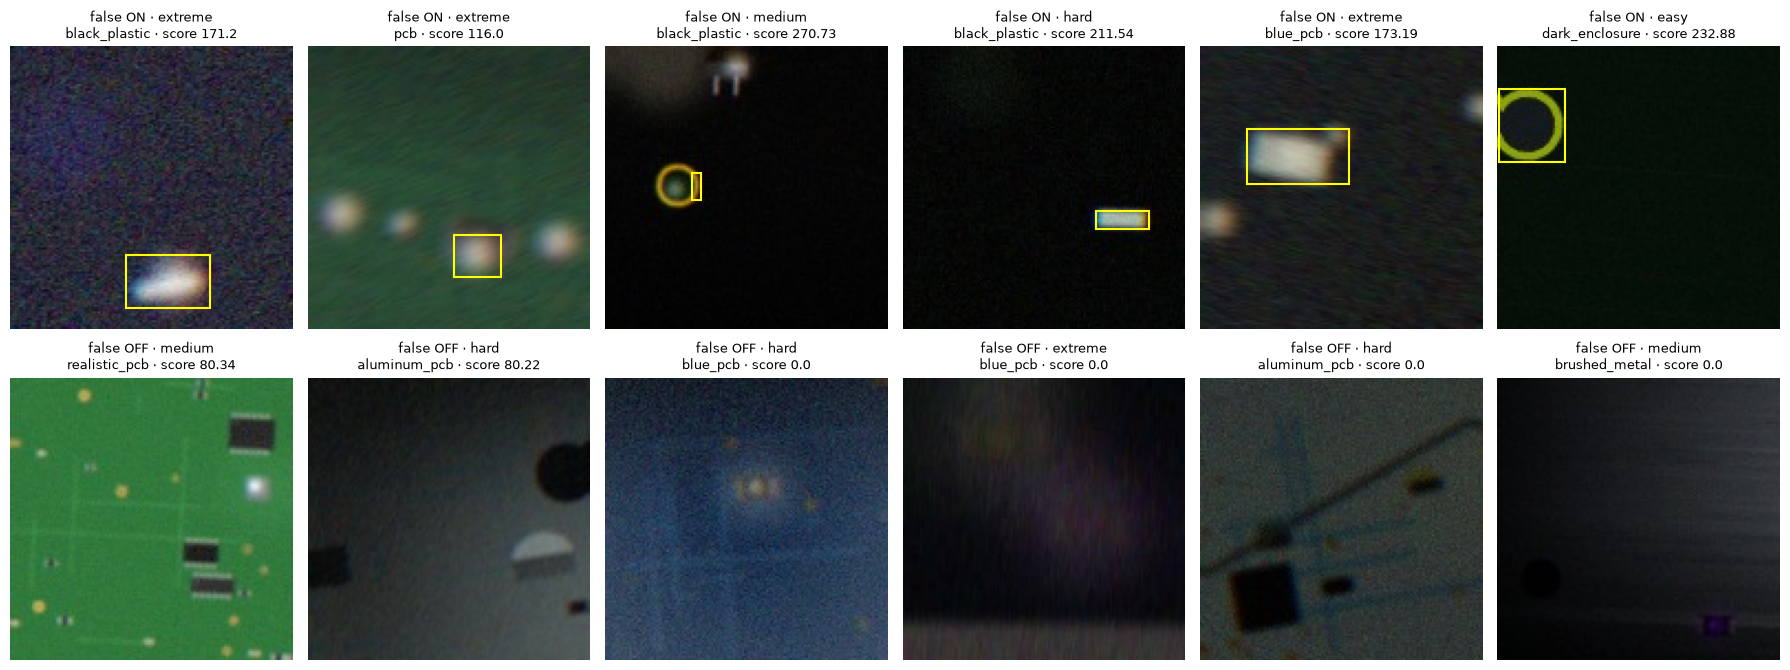

In [9]:
errors = {"false ON": [], "false OFF": []}
for s in test:
    img = cv2.imread(str(s.path))
    r = detector.detect(img)
    kind = "false ON" if (s.state, r.state) == ("OFF", "ON") else "false OFF" if (s.state, r.state) == ("ON", "OFF") else None
    if kind and len(errors[kind]) < 6:
        errors[kind].append((s, img, r))
    if all(len(v) == 6 for v in errors.values()):
        break

fig, axes = plt.subplots(2, 6, figsize=(18, 7))
for row_axes, (kind, items) in zip(axes, errors.items()):
    for ax, (s, img, r) in zip(row_axes, items):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if r.bbox:
            h, w = img.shape[:2]
            ax.add_patch(plt.Rectangle((r.bbox.x * w, r.bbox.y * h), r.bbox.width * w, r.bbox.height * h,
                                       fill=False, color="yellow", lw=1.5))
        ax.set_title(f"{kind} · {s.difficulty}\n{s.background} · score {r.debug['score']}", fontsize=9)
        ax.axis("off")
fig.tight_layout()
plt.show()

## Takeaways
* Accuracy falls steadily from easy to extreme scenes. On extreme scenes HSV is **below chance**: strong
  reflections score like lit LEDs, while dim LEDs barely rise above the background.
* False ON errors come from reflections, shiny SMD pads and bright patches of directional light; false OFF
  errors from dim, small or partly covered LEDs.
* HSV is extremely fast (a few milliseconds per image on a CPU) and fully explainable, which makes it a useful
  baseline and a fallback, but not a reliable detector under realistic conditions.

The next methods (template matching, KNN on hand-crafted features, a small CNN and a fine-tuned YOLOv8-nano)
are evaluated with exactly the same runner and test split.